In [20]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [21]:
import sys
from pathlib import Path

root = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()
)
sys.path.append(str(root / "src"))

from notebook_cache import NotebookCache

# results and prints live on disk, so they survive kernel restarts; one folder per notebook
cache = NotebookCache(root / "cache" / "ppo")

In [22]:
import gymnasium as gym
import numpy as np
import torch
import torch.nn as nn

device = "cuda" if torch.cuda.is_available() else "cpu"
env = gym.wrappers.RecordEpisodeStatistics(
    gym.make("CartPole-v1")
)  # info["episode"]["r"] at episode end


def make_policy():
    return nn.Sequential(
        nn.Linear(4, 128),
        nn.ReLU(),
        nn.Linear(128, 2),  # logits, one per action
    ).to(device)


def make_value():
    return nn.Sequential(
        nn.Linear(4, 128), nn.ReLU(),
        nn.Linear(128, 1),
    ).to(device)

## Step 1: collect a fixed number of steps

Until now, one update = one episode. PPO instead runs the policy for a fixed `n_steps` (crossing episode boundaries), then does many updates on that batch.

Two things the batch must carry that it didn't before:

- `logp`: the log-prob of each action **under the policy that collected it**. Later updates change the policy; PPO compares the new log-prob against this old one.
- `T` vs `D`: `T` (pole fell) zeroes the future value in the TD target; `D` (episode over, fell **or** time limit) stops the GAE sum from leaking into the next episode. A time limit isn't death, so it gets `D=1` but `T=0`.


In [23]:
def collect(env, policy, s, n_steps):
    """Run the policy for exactly n_steps, crossing episode boundaries.
    Returns (batch, s to resume from, returns of episodes that finished)."""
    states, actions, logps, rewards, next_states, terms, dones = (
        [], [], [], [],
        [], [], [],
    )
    ep_returns = []
    for _ in range(n_steps):
        with torch.no_grad():
            dist = torch.distributions.Categorical(
                logits=policy(torch.tensor(s, dtype=torch.float32, device=device))
            )
            a = dist.sample()
        s2, r, term, trunc, info = env.step(a.item())
        states.append(s)
        actions.append(a.item())
        logps.append(
            dist.log_prob(a).item()
        )  # old log-prob: PPO compares against it later
        rewards.append(r)
        next_states.append(s2)
        terms.append(float(term))  # pole fell: no future value
        dones.append(float(term or trunc))  # episode over either way: GAE stops here
        if term or trunc:
            ep_returns.append(info["episode"]["r"])
            s, _ = env.reset()
        else:
            s = s2

    f = lambda x: torch.tensor(np.array(x), dtype=torch.float32, device=device)
    batch = dict(
        S=f(states),
        A=f(actions).long(),
        logp=f(logps),
        R=f(rewards),
        S2=f(next_states),
        T=f(terms),
        D=f(dones),
    )
    return batch, s, ep_returns

In [24]:
policy = make_policy()
s, _ = env.reset(seed=0)
batch, s, ep_returns = collect(env, policy, s, n_steps=2048)
for k, v in batch.items():
    print(f"{k:5s} {tuple(v.shape)}")
print("episodes finished:", len(ep_returns), " mean return:", np.mean(ep_returns))
print("episode ends in batch:", int(batch["D"].sum().item()))

S     (2048, 4)
A     (2048,)
logp  (2048,)
R     (2048,)
S2    (2048, 4)
T     (2048,)
D     (2048,)
episodes finished: 86  mean return: 23.75581395348837
episode ends in batch: 86


## Step 2: GAE on the batch

Same backward sum as `policy_gradients` cell 11, with one change: the two jobs `D` did there are split.

- `(1 - T)` in the delta: only a real fall zeroes the next state's value. At a time limit we still bootstrap from `V(s')`.
- `(1 - D)` in the sum: any episode end stops the sum, so advantages don't leak across episodes.

The batch's last step is usually mid-episode. Nothing special needed: its delta bootstraps from `V(s')`, and the sum just starts there.


In [25]:
def gae(value, batch, gamma=0.99, lam=0.95):
    """Advantages and value targets for one batch. No gradients: they're fixed labels."""
    with torch.no_grad():
        V = value(batch["S"]).squeeze(1)
        V2 = value(batch["S2"]).squeeze(1)
        deltas = batch["R"] + gamma * V2 * (1 - batch["T"]) - V  # T: fell -> no future
        adv = torch.zeros_like(deltas)
        A = 0.0
        for t in reversed(range(len(deltas))):
            A = (
                deltas[t] + gamma * lam * (1 - batch["D"][t]) * A
            )  # D: episode over -> restart the sum
            adv[t] = A
    return adv, adv + V  # adv + V = value target, same as cell 11

In [26]:
value = make_value()
adv, target = gae(value, batch)
print("adv   ", tuple(adv.shape), f"mean={adv.mean():.2f}  std={adv.std():.2f}")

# check: lam=1 should give plain discounted returns, G_t - V(s_t), within an episode
adv1, target1 = gae(value, batch, lam=1.0)
end = int(batch["D"].nonzero()[0])  # last step of the first episode
G, Gs = 0.0, []
for r in reversed(batch["R"][: end + 1].tolist()):
    G = r + 0.99 * G
    Gs.append(G)
Gs = torch.tensor(list(reversed(Gs)), device=device)
print(
    "lam=1 target == discounted return:",
    torch.allclose(target1[: end + 1], Gs, atol=1e-4),
)

adv    (2048,) mean=8.84  std=4.16
lam=1 target == discounted return: True


## Step 3: the clipped update

Reuse the batch for several epochs of minibatches. The danger: after a few updates the policy is no longer the one that collected the data, and pushing too hard on stale data wrecks it.

`ratio = π_new(a|s) / π_old(a|s)` measures that drift per action. The loss:

    min( ratio · A,  clip(ratio, 0.8, 1.2) · A )

- `A > 0` (good action): gain grows with the ratio until 1.2, then flat. No reward for pushing it further.
- `A < 0` (bad action): same, until 0.8.
- The `min` keeps the **worse** of the two, so the clip only ever removes incentive, never adds it.

Clipping isn't a hard wall: it zeroes the gradient for clipped samples, but other samples' updates can still move them. That's why we watch two diagnostics:

- `clipfrac`: share of samples clipped. ~0.1–0.2 is healthy.
- `kl`: how far the policy moved overall. ~0.01–0.02 is typical; much higher means the lr or epochs are too aggressive.


In [27]:
def ppo_update(
    policy, value, opt, opt_v, batch, adv,
    target, epochs=10, mb_size=64,
    clip=0.2, ent_coef=0.0, max_grad=0.5,
):
    """Several epochs of minibatch updates on one batch. Returns averaged diagnostics."""
    stats = []
    for _ in range(epochs):
        for idx in torch.randperm(len(adv), device=device).split(mb_size):
            S, A, old_logp = batch["S"][idx], batch["A"][idx], batch["logp"][idx]
            a = adv[idx]
            a = (a - a.mean()) / (a.std() + 1e-8)

            dist = torch.distributions.Categorical(logits=policy(S))
            logp = dist.log_prob(A)
            ratio = (
                logp - old_logp
            ).exp()  # how much more/less likely than when collected
            policy_loss = -torch.min(
                ratio * a, ratio.clamp(1 - clip, 1 + clip) * a
            ).mean()
            entropy = dist.entropy().mean()
            value_loss = nn.functional.mse_loss(value(S).squeeze(1), target[idx])

            opt.zero_grad()
            (policy_loss - ent_coef * entropy).backward()
            nn.utils.clip_grad_norm_(policy.parameters(), max_grad)
            opt.step()
            opt_v.zero_grad()
            value_loss.backward()
            nn.utils.clip_grad_norm_(value.parameters(), max_grad)
            opt_v.step()

            with torch.no_grad():
                stats.append(
                    [
                        policy_loss.item(),
                        value_loss.item(),
                        entropy.item(),
                        ((ratio - 1).abs() > clip)
                        .float()
                        .mean()
                        .item(),  # clip fraction
                        ((ratio - 1) - ratio.log())
                        .mean()
                        .item(),  # approx KL(old || new)
                    ]
                )
    return dict(
        zip(
            ["policy_loss", "value_loss", "entropy", "clipfrac", "kl"],
            np.mean(stats, 0),
        )
    )

In [28]:
opt = torch.optim.Adam(policy.parameters(), lr=3e-4)
opt_v = torch.optim.Adam(value.parameters(), lr=1e-3)
stats = ppo_update(policy, value, opt, opt_v, batch, adv, target)
for k, v in stats.items():
    print(f"{k:12s} {v:8.4f}")

# how far did the policy actually move on this batch?
with torch.no_grad():
    new_logp = torch.distributions.Categorical(logits=policy(batch["S"])).log_prob(
        batch["A"]
    )
    ratio = (new_logp - batch["logp"]).exp()
print(
    f"ratio after update: min={ratio.min():.2f}  max={ratio.max():.2f}  "
    f"outside [0.8, 1.2]: {((ratio - 1).abs() > 0.2).float().mean():.1%}"
)

policy_loss   -0.0174
value_loss    41.0112
entropy        0.6746
clipfrac       0.0494
kl             0.0070
ratio after update: min=0.74  max=1.19  outside [0.8, 1.2]: 5.7%


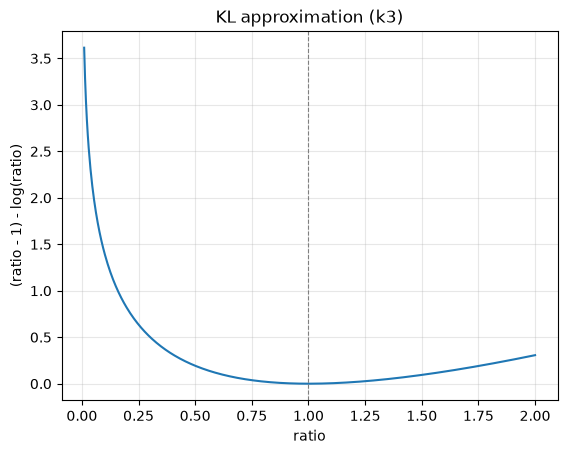

In [ ]:
import matplotlib.pyplot as plt
import torch

ratio = torch.linspace(0.01, 2, 500)
kl = (ratio - 1) - ratio.log()

plt.plot(ratio, kl)
plt.axvline(1, color="gray", linestyle="--", linewidth=0.8)
plt.xlabel("ratio")
plt.ylabel("(ratio - 1) - log(ratio)")
plt.title("KL approximation (k3)")
plt.grid(alpha=0.3)
plt.show()

## Step 4: the training loop

Just the three steps on repeat: `collect` → `gae` → `ppo_update`. `@cache` stores the result on disk, so rerunning the cell after a kernel restart replays it instantly. It's keyed on the arguments, so a new kwarg combination trains fresh.

Returns are logged against **env steps**, not episodes. Episodes get longer as the policy improves, so "per episode" makes good agents look slow. Env steps is the fair x-axis for comparing algorithms.


In [ ]:
@cache
def train_ppo(
    total_steps=100_000,
    n_steps=2048,
    gamma=0.99,
    lam=0.95,
    lr=3e-4,
    lr_v=1e-3,
    epochs=10,
    mb_size=64,
    clip=0.2,
    ent_coef=0.0,
    seed=0,
):
    torch.manual_seed(seed)
    env = gym.wrappers.RecordEpisodeStatistics(gym.make("CartPole-v1"))
    policy, value = make_policy(), make_value()
    opt = torch.optim.Adam(policy.parameters(), lr=lr)
    opt_v = torch.optim.Adam(value.parameters(), lr=lr_v)

    s, _ = env.reset(seed=seed)
    returns, ends, stats_log = (
        [], [], [],
    )  # ends[i]: env step at which episode i finished
    steps = 0
    while steps < total_steps:
        batch, s, ep_returns = collect(env, policy, s, n_steps)
        steps += n_steps
        adv, target = gae(value, batch, gamma, lam)
        stats = ppo_update(
            policy, value, opt, opt_v, batch, adv, target,
            epochs=epochs, mb_size=mb_size, clip=clip,
            ent_coef=ent_coef,
        )
        returns += ep_returns
        ends += [steps] * len(ep_returns)
        stats_log.append(stats)
        print(
            f"steps {steps:6d}  episodes {len(returns):4d}  avg20={np.mean(returns[-20:]):6.1f}  "
            f"kl={stats['kl']:.4f}  clipfrac={stats['clipfrac']:.2f}"
        )

    return dict(policy=policy, value=value, returns=returns, ends=ends, stats=stats_log)

train_ppo: cached, 1 call(s) stored


In [30]:
res = train_ppo()

steps   2048  episodes   95  avg20=  25.0  kl=0.0104  clipfrac=0.17
steps   4096  episodes  168  avg20=  25.8  kl=0.0093  clipfrac=0.13
steps   6144  episodes  219  avg20=  34.5  kl=0.0086  clipfrac=0.11
steps   8192  episodes  258  avg20=  46.0  kl=0.0063  clipfrac=0.07
steps  10240  episodes  282  avg20=  81.5  kl=0.0058  clipfrac=0.05
steps  12288  episodes  300  avg20= 107.5  kl=0.0055  clipfrac=0.06
steps  14336  episodes  313  avg20= 134.9  kl=0.0078  clipfrac=0.10
steps  16384  episodes  326  avg20= 148.9  kl=0.0037  clipfrac=0.04
steps  18432  episodes  334  avg20= 187.7  kl=0.0040  clipfrac=0.04
steps  20480  episodes  340  avg20= 249.1  kl=0.0050  clipfrac=0.05
steps  22528  episodes  344  avg20= 306.8  kl=0.0078  clipfrac=0.10
steps  24576  episodes  350  avg20= 361.1  kl=0.0034  clipfrac=0.03
steps  26624  episodes  354  avg20= 409.6  kl=0.0035  clipfrac=0.04
steps  28672  episodes  358  avg20= 433.4  kl=0.0034  clipfrac=0.03
steps  30720  episodes  363  avg20= 438.1  kl=0.

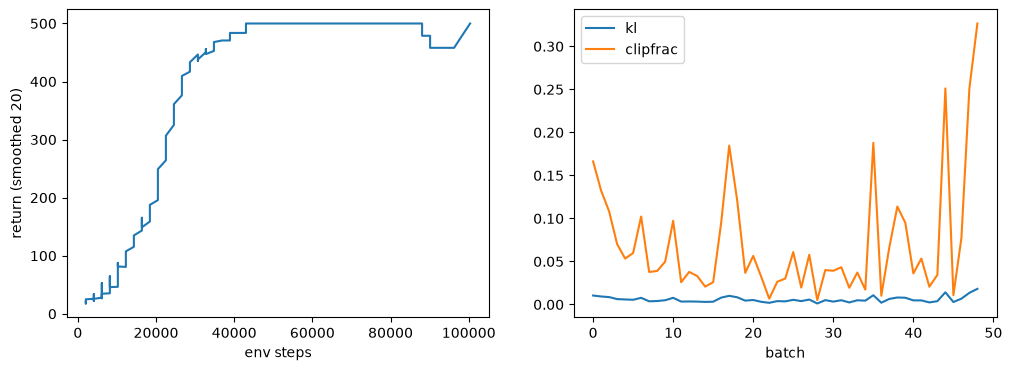

In [31]:
import matplotlib.pyplot as plt


def smooth(xs, k=20):
    return np.convolve(xs, np.ones(k) / k, mode="valid")


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(res["ends"][19:], smooth(res["returns"]))
ax1.set_xlabel("env steps")
ax1.set_ylabel("return (smoothed 20)")
ax2.plot([st["kl"] for st in res["stats"]], label="kl")
ax2.plot([st["clipfrac"] for st in res["stats"]], label="clipfrac")
ax2.set_xlabel("batch")
ax2.legend()
plt.show()